# 02 — OCR
Run with .venvOCR. Cached raw OCR is reused; cleanup does not call OCR again.

PaddleOCR retains the existing local installation/model cache behavior.

In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / "project.json").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pipeline_helpers as P
import json
from PIL import Image, ImageDraw, ImageFont
ROOT = P.ROOT
MODELS = P.read_json(ROOT / "models.json")
SPLITS = ["train", "val"]  # Or ["train"] / ["val"].
FORCE_RERUN = False
items = P.pages(SPLITS)
print("Pages:", len(items))
import numpy as np
from paddleocr import PaddleOCR
from importlib.metadata import version
LANGUAGE = "en"
ocr = None


Pages: 240


c:\Users\ESHAAN\BYTE\Applied-Task\1pageTest\.venvOCR\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OCR only uncached pages. Initialization occurs only when needed.

In [3]:
for item in items:
    PAGE = Path(item["image_path"])
    page = Image.open(PAGE).convert("RGB")
    OUT = P.page_folder(item)
    OUT.mkdir(parents=True, exist_ok=True)
    settings = {"language":LANGUAGE, "paddleocr":version("paddleocr"), "version":1}
    dependencies = [OUT / "bubbles.json"]
    def save_stage(name, records):
        P.save_stage(item, name, records, settings, dependencies)
    def load_stage(name):
        return P.load_stage(item, name)
    if all(P.cached(item, name, settings, dependencies, FORCE_RERUN) for name in ['ocr.json']):
        print("Cached:", item["split"], item["sequence_id"], item["page_number"])
        continue
    bubbles = load_stage("bubbles.json")
    if ocr is None:
        ocr = PaddleOCR(lang=LANGUAGE, use_doc_orientation_classify=False,
            use_doc_unwarping=False, use_textline_orientation=False)
    CROPS = OUT / "bubble_crops"
    CROPS.mkdir(exist_ok=True)
    ocr_results = []
    for bubble in bubbles:
        crop = page.crop(bubble["box"])
        crop.save(CROPS / f"{bubble['bubble_id']}.png")
        lines = []
        for result in ocr.predict(input=np.asarray(crop)):
            for text, score in zip(result["rec_texts"], result["rec_scores"]):
                lines.append({"text": str(text), "confidence": float(score)})
        ocr_results.append({"bubble_id": bubble["bubble_id"], "box": bubble["box"],
                            "text": " ".join(line["text"] for line in lines), "lines": lines})
    save_stage("ocr.json", ocr_results)


Cached: train seq_2032620aa4e4ac7f 1
Cached: train seq_2032620aa4e4ac7f 2
Cached: train seq_2032620aa4e4ac7f 3
Cached: train seq_952f154fb1505883 1
Cached: train seq_952f154fb1505883 2
Cached: train seq_952f154fb1505883 3
Cached: train seq_7db7a000adeceacf 1
Cached: train seq_7db7a000adeceacf 2
Cached: train seq_7db7a000adeceacf 3
Cached: train seq_9032e5551cf1a9d2 1
Cached: train seq_9032e5551cf1a9d2 2
Cached: train seq_9032e5551cf1a9d2 3
Cached: train seq_2022b8c0e1f2d3c0 1
Cached: train seq_2022b8c0e1f2d3c0 2
Cached: train seq_2022b8c0e1f2d3c0 3
Cached: train seq_a3bd36201a0cd61b 1
Cached: train seq_a3bd36201a0cd61b 2
Cached: train seq_a3bd36201a0cd61b 3
Cached: train seq_72fdfff4b4353a42 1
Cached: train seq_72fdfff4b4353a42 2
Cached: train seq_72fdfff4b4353a42 3
Cached: train seq_b251c8e1ba8b91f8 1
Cached: train seq_b251c8e1ba8b91f8 2
Cached: train seq_b251c8e1ba8b91f8 3
Cached: val seq_ee880b9612205860 1
Cached: val seq_ee880b9612205860 2
Cached: val seq_ee880b9612205860 3
Cached:

## View saved results
These cells only read saved results. They do not run models or change cached files. Training shows targets and run-wide loss history; validation shows saved predictions.

In [4]:
from pathlib import Path
import sys, importlib
view_root = Path.cwd().resolve()
if not (view_root / "project.json").is_file():
    view_root = view_root.parent
sys.path.insert(0, str(view_root))
import result_viewer as V
importlib.reload(V)
VIEW_STAGE = 'ocr'
VIEW_SPLIT = "train"  # Or "val".
VIEW_RUN = None


### 1. View a random page
Rerun this cell to choose another page with a saved result in this split.


train | seq_098e260f231aa789 | page 2


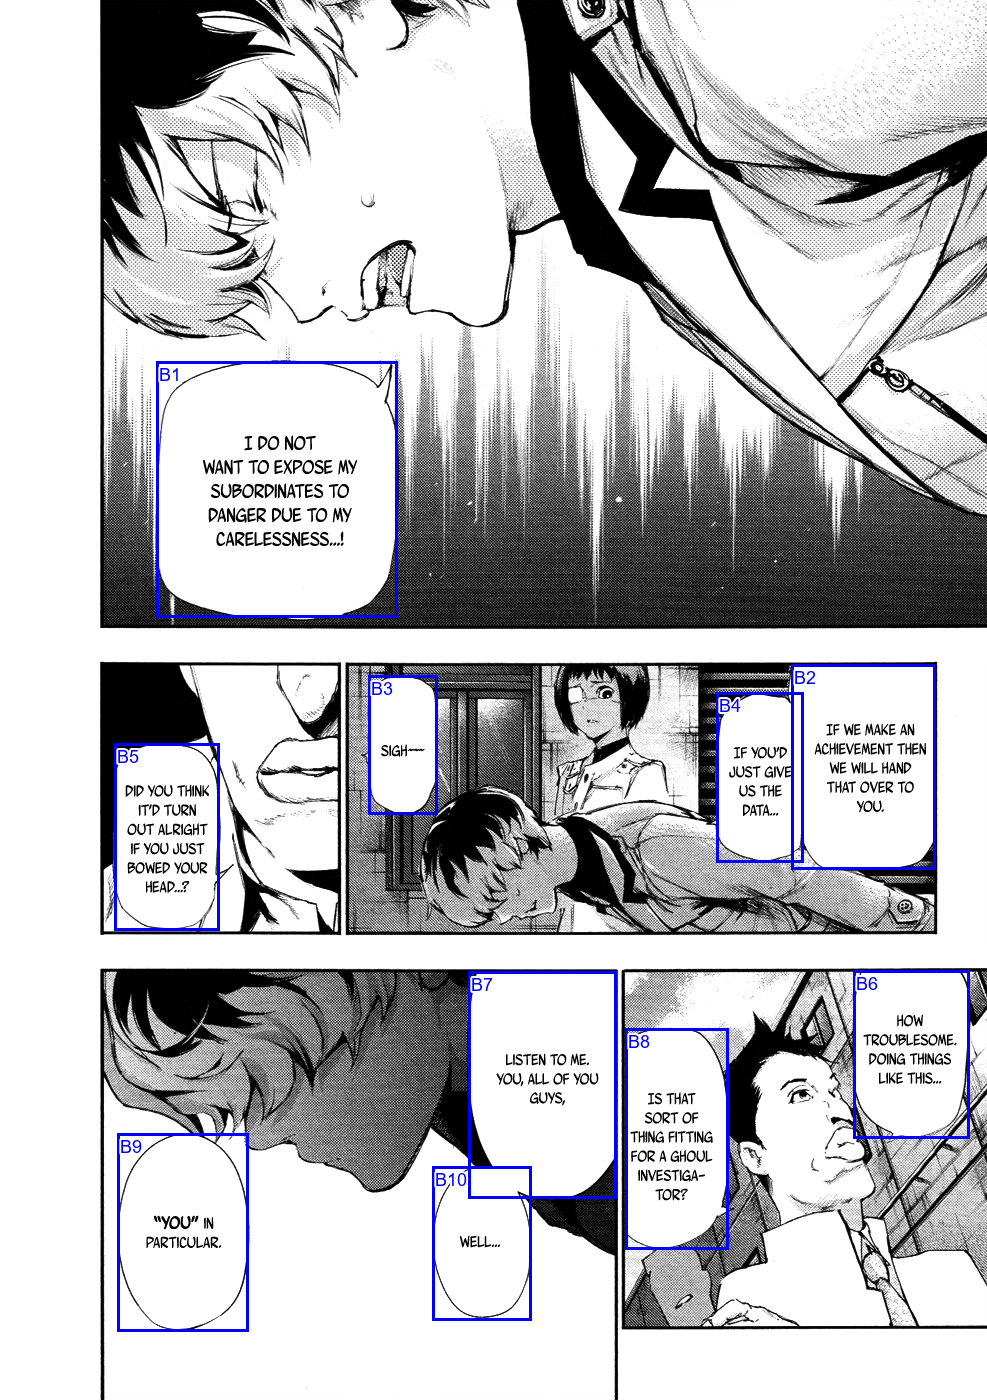

[
  {
    "bubble_id": "B1",
    "box": [
      156,
      361,
      397,
      617
    ],
    "text": "I DO NOT WANT TO EXPOSE MY SUBORDINATES TO DANGER DUE TO MY CARELESSNESS..!",
    "lines": [
      {
        "text": "I DO NOT",
        "confidence": 0.925603985786438
      },
      {
        "text": "WANT TO EXPOSE MY",
        "confidence": 0.999663770198822
      },
      {
        "text": "SUBORDINATES TO",
        "confidence": 0.9998158812522888
      },
      {
        "text": "DANGER DUE TO MY",
        "confidence": 0.9772695302963257
      },
      {
        "text": "CARELESSNESS..!",
        "confidence": 0.993763267993927
      }
    ]
  },
  {
    "bubble_id": "B2",
    "box": [
      791,
      664,
      935,
      869
    ],
    "text": "IF WE MAKE AN ACHIEVEMENT THEN WE WILL HAND THAT OVER TO YOU.",
    "lines": [
      {
        "text": "IF WE MAKE AN",
        "confidence": 0.9926939606666565
      },
      {
        "text": "ACHIEVEMENT THEN",
        "confiden

In [5]:
viewed_page = V.show_random(VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)


### 2. View all pages of a sequence
Enter a sequence ID, or leave it empty to use the random page’s sequence. Missing stage results are reported for each page.


train | seq_0dc2e3d874c804fc | page 1


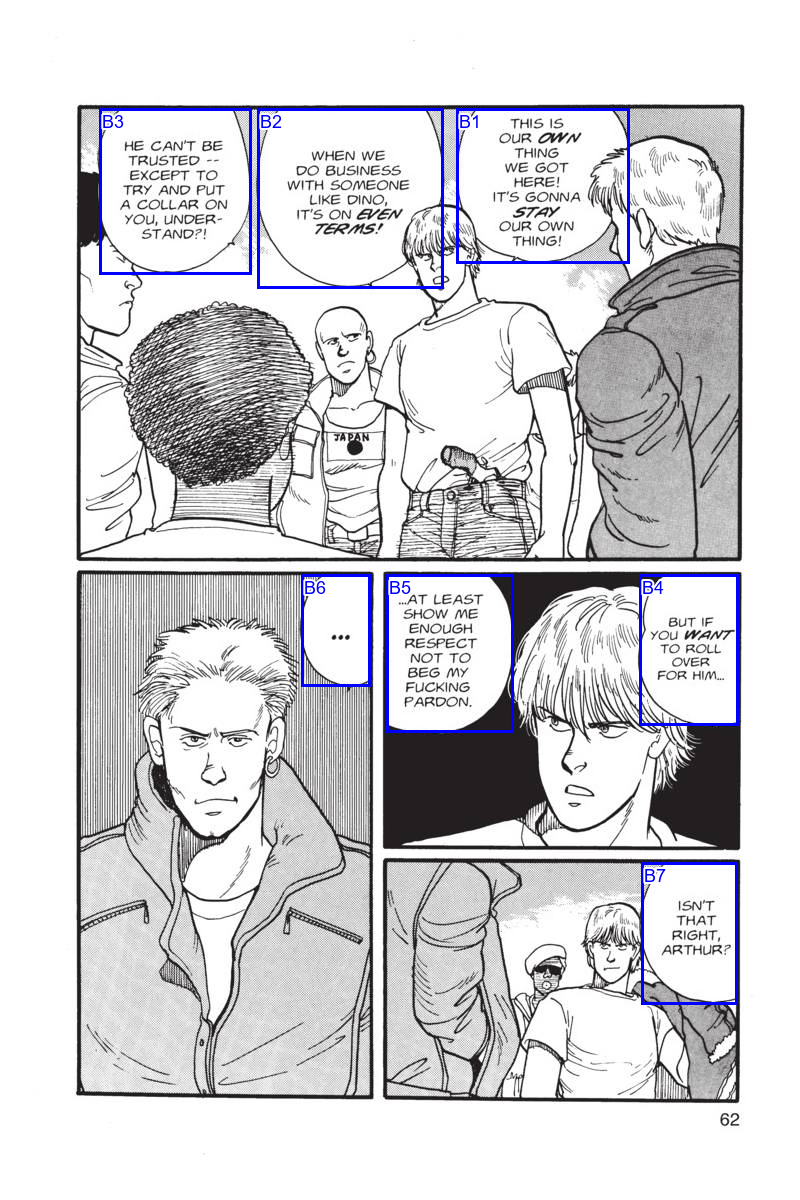

[
  {
    "bubble_id": "B1",
    "box": [
      456,
      108,
      629,
      263
    ],
    "text": "THIS IS OUR OWN THING WE GOT HERE! IT'S GONNA STAY OUR OWN THING!",
    "lines": [
      {
        "text": "THIS IS",
        "confidence": 0.9783240556716919
      },
      {
        "text": "OUR OWN",
        "confidence": 0.9962936043739319
      },
      {
        "text": "THING",
        "confidence": 0.9999898076057434
      },
      {
        "text": "WE GOT",
        "confidence": 0.9727973937988281
      },
      {
        "text": "HERE!",
        "confidence": 0.9999553561210632
      },
      {
        "text": "IT'S GONNA",
        "confidence": 0.9999315142631531
      },
      {
        "text": "STAY",
        "confidence": 0.99998939037323
      },
      {
        "text": "OUR OWN",
        "confidence": 0.9985760450363159
      },
      {
        "text": "THING!",
        "confidence": 0.9999783635139465
      }
    ]
  },
  {
    "bubble_id": "B2",
    "box": [
     

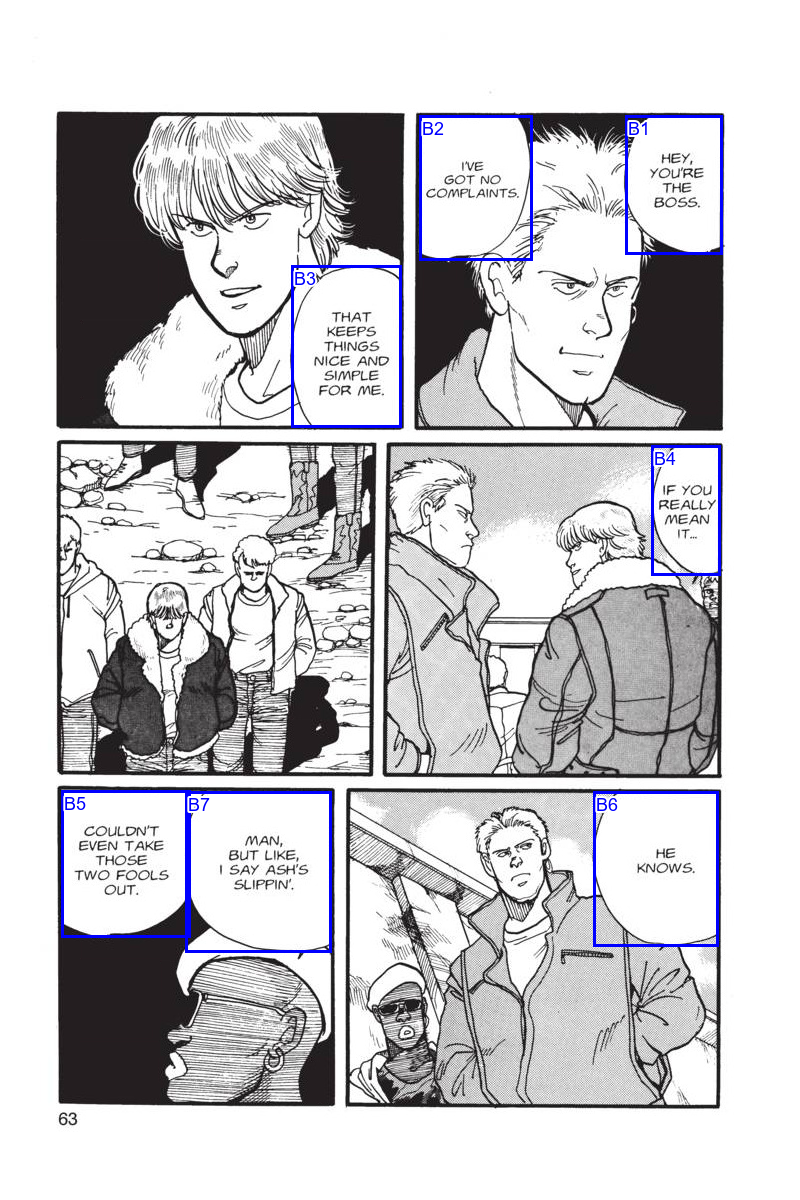

[
  {
    "bubble_id": "B1",
    "box": [
      625,
      115,
      722,
      254
    ],
    "text": "HEY, YOU'RE THE BOSS.",
    "lines": [
      {
        "text": "HEY,",
        "confidence": 0.997765302658081
      },
      {
        "text": "YOU'RE",
        "confidence": 0.9998953938484192
      },
      {
        "text": "THE",
        "confidence": 0.9999879002571106
      },
      {
        "text": "BOSS.",
        "confidence": 0.9999222755432129
      }
    ]
  },
  {
    "bubble_id": "B2",
    "box": [
      419,
      115,
      532,
      260
    ],
    "text": "I'VE GOT NO COMPLAINTS",
    "lines": [
      {
        "text": "I'VE",
        "confidence": 0.9946228861808777
      },
      {
        "text": "GOT NO",
        "confidence": 0.9949777722358704
      },
      {
        "text": "COMPLAINTS",
        "confidence": 0.9999699592590332
      }
    ]
  },
  {
    "bubble_id": "B3",
    "box": [
      291,
      265,
      401,
      427
    ],
    "text": "THAT KE

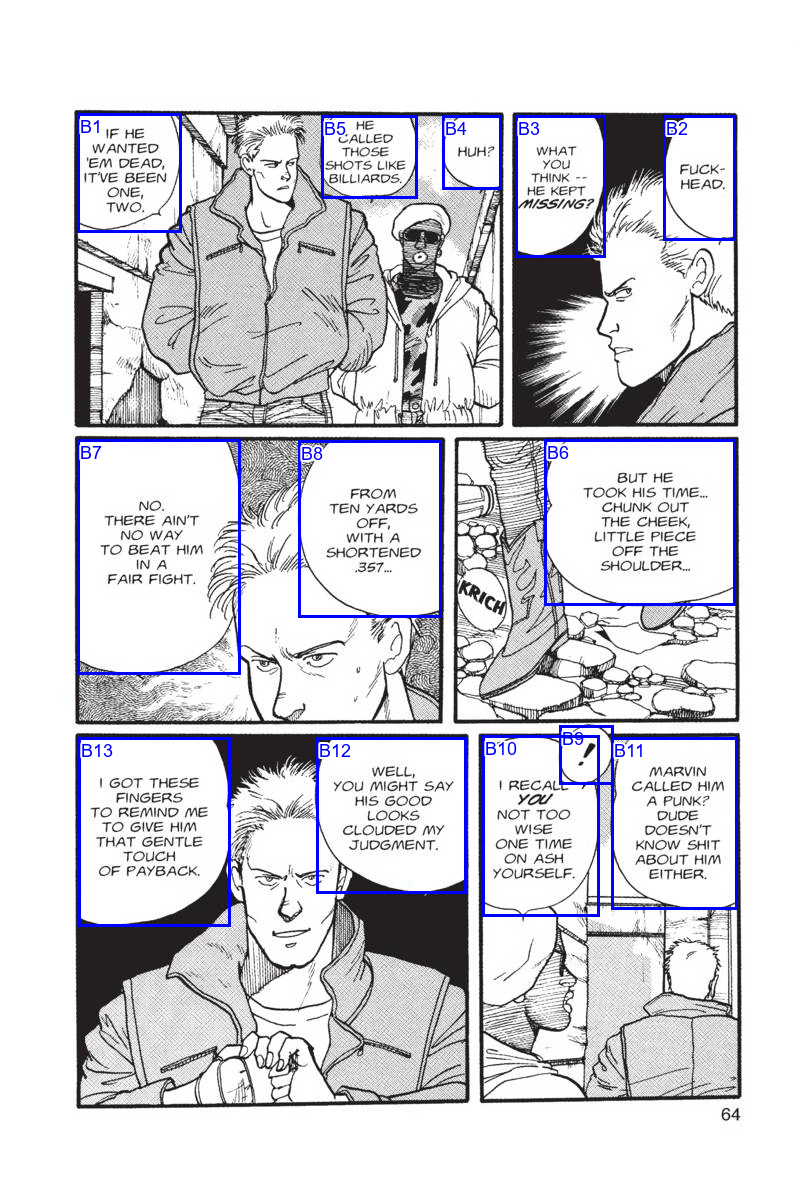

[
  {
    "bubble_id": "B1",
    "box": [
      77,
      113,
      181,
      232
    ],
    "text": "IF HE WANTED 'EM DEAD, IT'VE BEEN ONE, TWO.",
    "lines": [
      {
        "text": "IF HE",
        "confidence": 0.971982479095459
      },
      {
        "text": "WANTED",
        "confidence": 0.9999753832817078
      },
      {
        "text": "'EM DEAD,",
        "confidence": 0.9986746311187744
      },
      {
        "text": "IT'VE BEEN",
        "confidence": 0.9996822476387024
      },
      {
        "text": "ONE,",
        "confidence": 0.9997707605361938
      },
      {
        "text": "TWO.",
        "confidence": 0.9988129734992981
      }
    ]
  },
  {
    "bubble_id": "B2",
    "box": [
      663,
      115,
      735,
      240
    ],
    "text": "FUCK- HEAD.",
    "lines": [
      {
        "text": "FUCK-",
        "confidence": 0.9969518780708313
      },
      {
        "text": "HEAD.",
        "confidence": 0.9997770190238953
      }
    ]
  },
  {
    "bub

In [6]:
VIEW_SEQUENCE_ID = "seq_0dc2e3d874c804fc"  # Example: "seq_71033fec4de494fc"
sequence_to_view = VIEW_SEQUENCE_ID or (viewed_page["sequence_id"] if viewed_page else "")
if sequence_to_view:
    V.show_sequence(sequence_to_view, VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)
else:
    print("Set VIEW_SEQUENCE_ID to a sequence in VIEW_SPLIT.")
